In [ ]:
# outdated

In [1]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/../utils/train_utils.py'>

In [3]:
# read_ids = list(range(0, 13+1))
read_ids = [0, 3, 11]
plot_id = 11

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
print(traces[0].shape)

(10219, 1559)


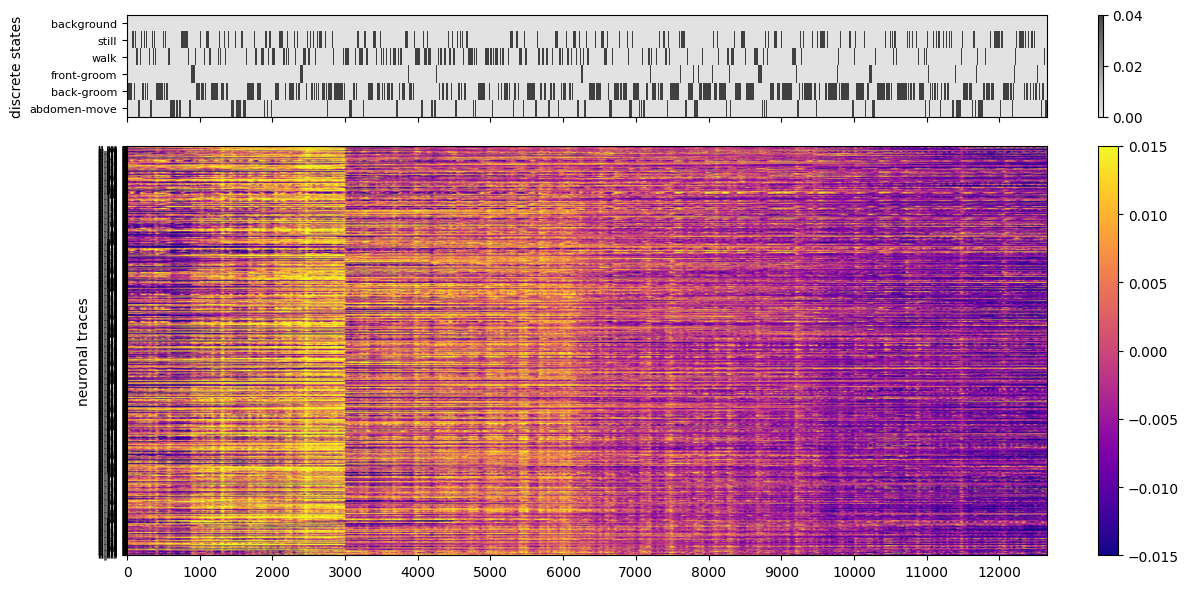

In [29]:
# plot
plot_utils.plot_heatmap_stack(traces[file_ids.index(plot_id)], states[file_ids.index(plot_id)], 'neuronal traces', 'discrete states',
							  ylimits_top=(0., 0.04))

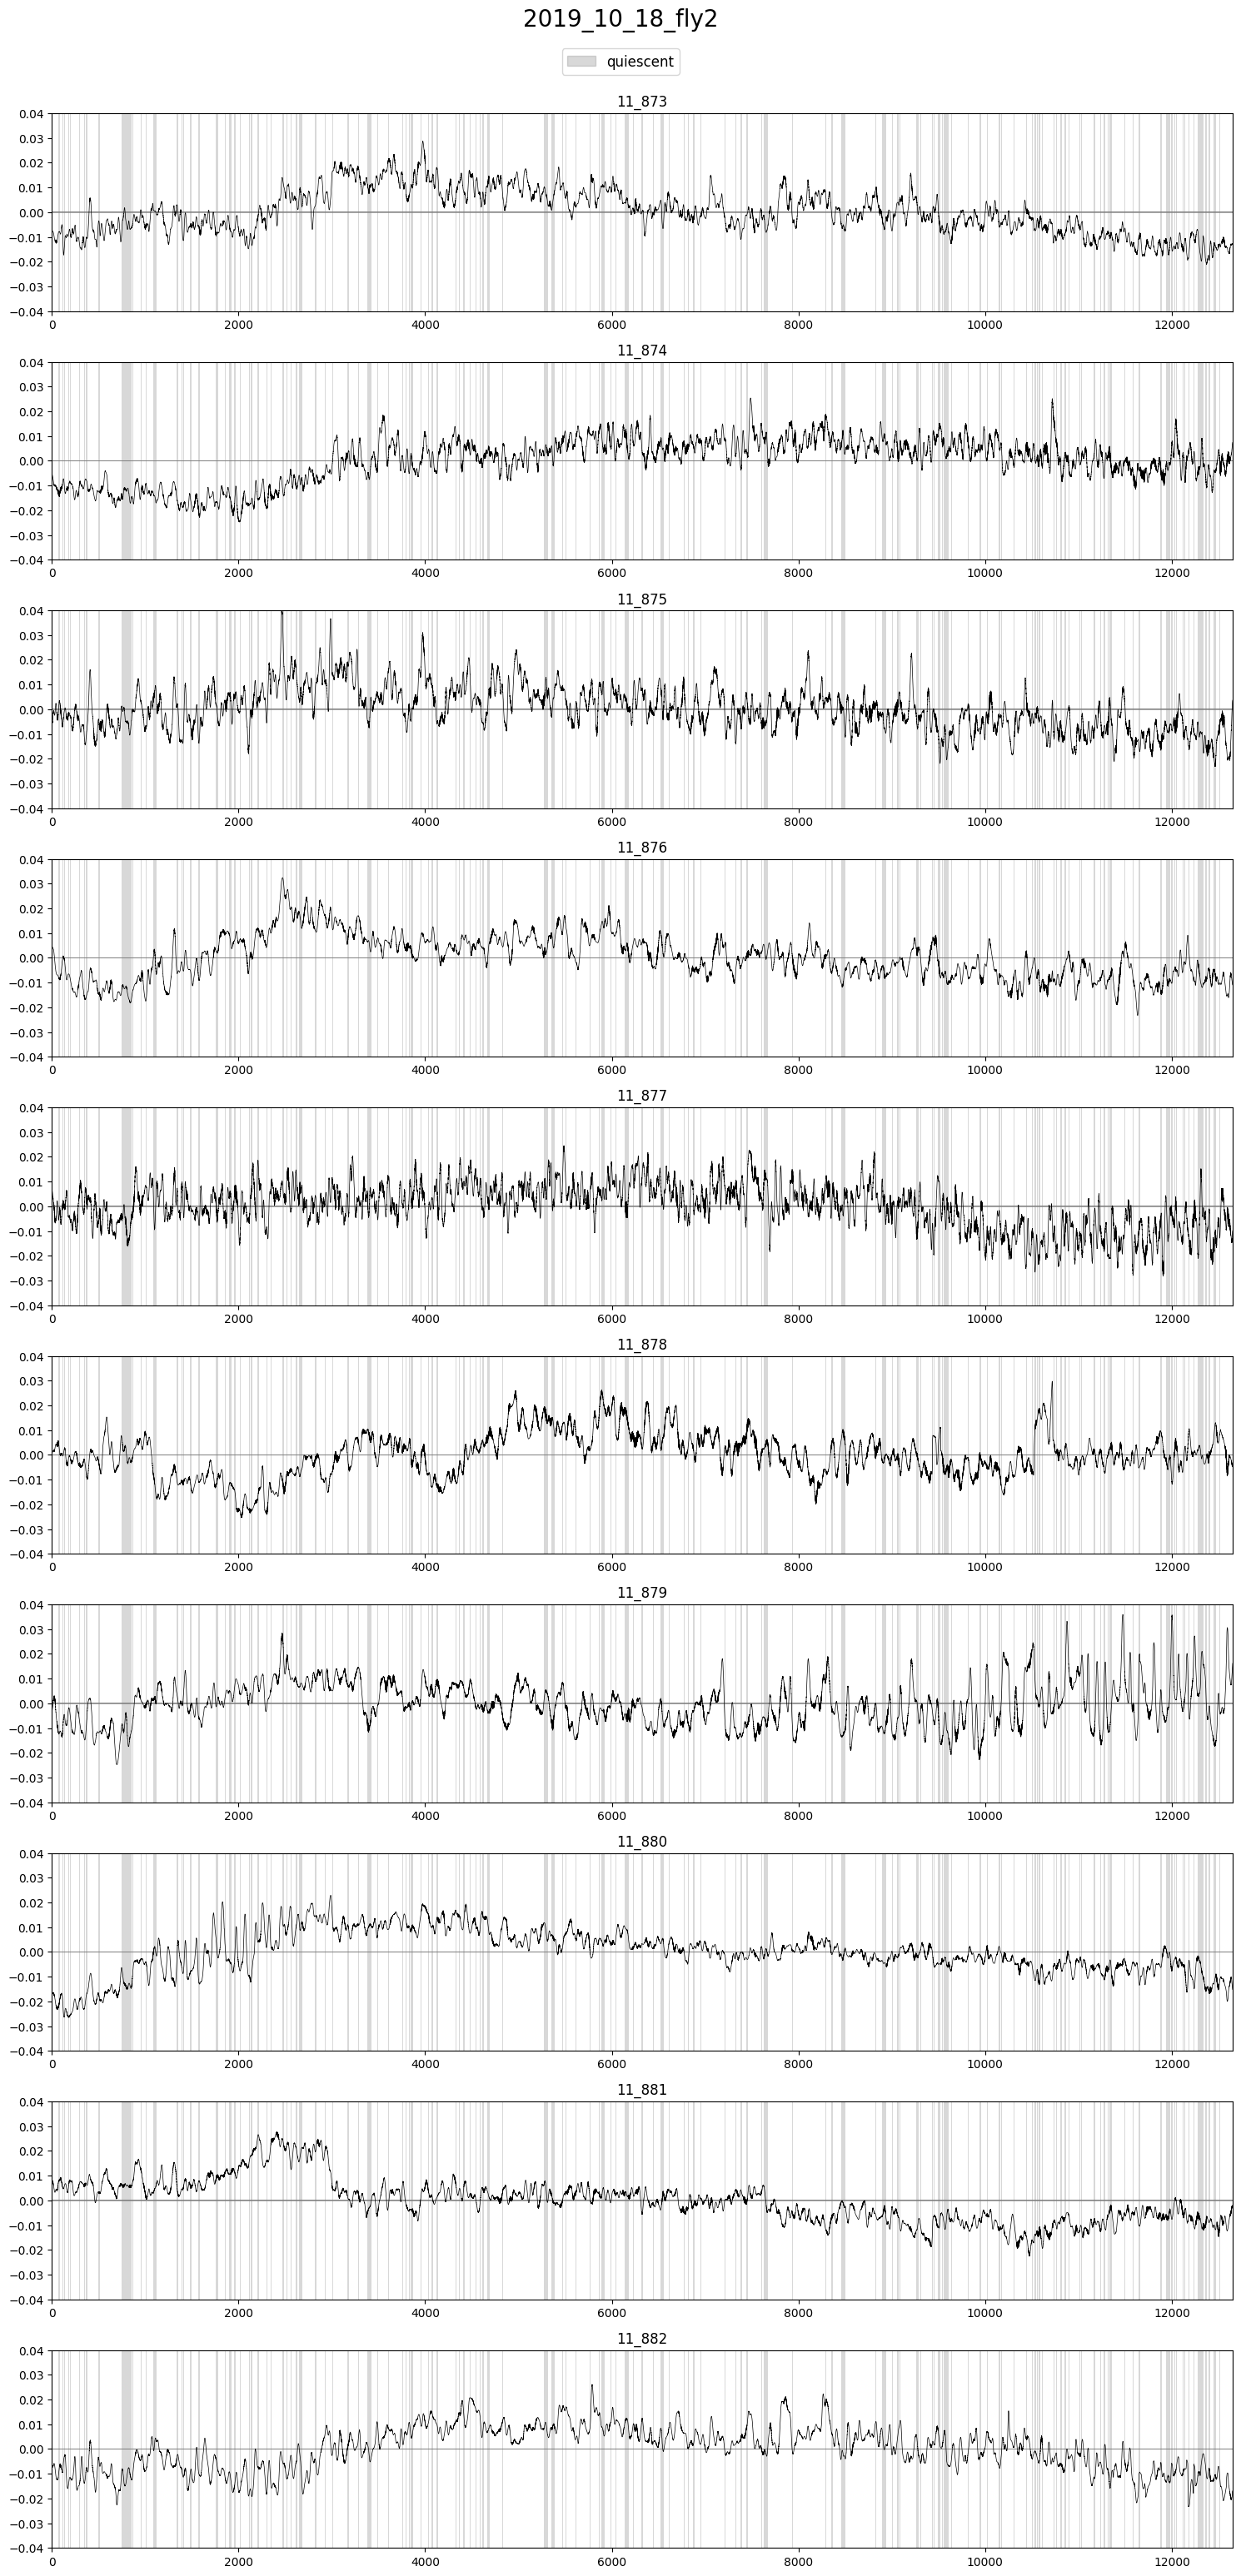

In [36]:
plot_utils.plot_traces(f'{filenames[file_ids.index(plot_id)]}',
					   states[file_ids.index(plot_id)]['still'],
					   [traces[file_ids.index(plot_id)].iloc[:, -10:]],
					   label='quiescent', n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))

# flail

In [31]:
# read_ids_fl = list(range(0, 9+1))
read_ids_fl = [1, 4, 5]
plot_id_fl = 4

In [32]:
path_fl = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain/incomplete/no_pickle/flailing')

(file_ids_fl, filenames_fl,
 traces_fl,
 states_fl, markers_fl) = read_utils.get_data(path_fl, read_ids_fl, with_markers=False)

# # clear nan values
# for i in range(len(file_ids_fl)):
# 	mask = markers_fl[i].notna().all(axis=1)
#
# 	traces_fl[i] = traces_fl[i][mask]
# 	markers_fl[i] = markers_fl[i][mask]
# 	states_fl[i] = states_fl[i][mask]
#
# 	#filenames_fl[i] = filenames_fl[i][mask]

# # remove unused discrete state labels
# states_fl = [ds[selection_bhl] for ds in states_fl]

# naive ID unknown neurons
for i in range(len(file_ids_fl)):
	traces_fl[i].columns = pd.Index([
		f'{file_ids_fl[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_fl[i].columns, traces_fl[i].columns == ''))
	])

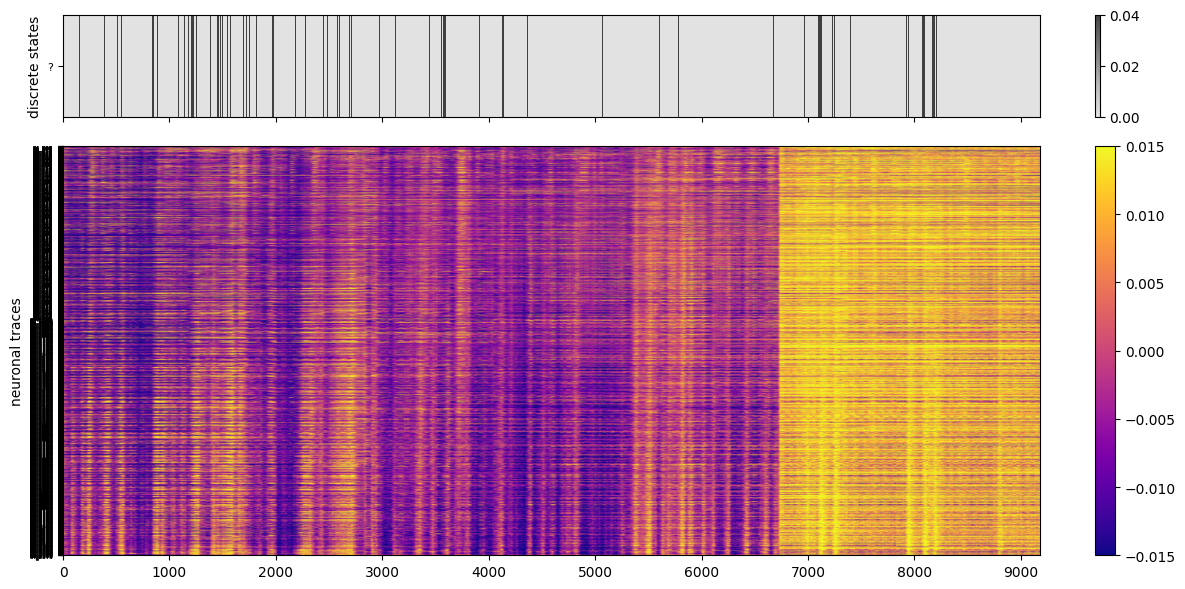

In [33]:
# plot
plot_utils.plot_heatmap_stack(traces_fl[file_ids_fl.index(plot_id_fl)], states_fl[file_ids_fl.index(plot_id_fl)], 'neuronal traces', 'discrete states',
							  ylimits_top=(0., 0.04))

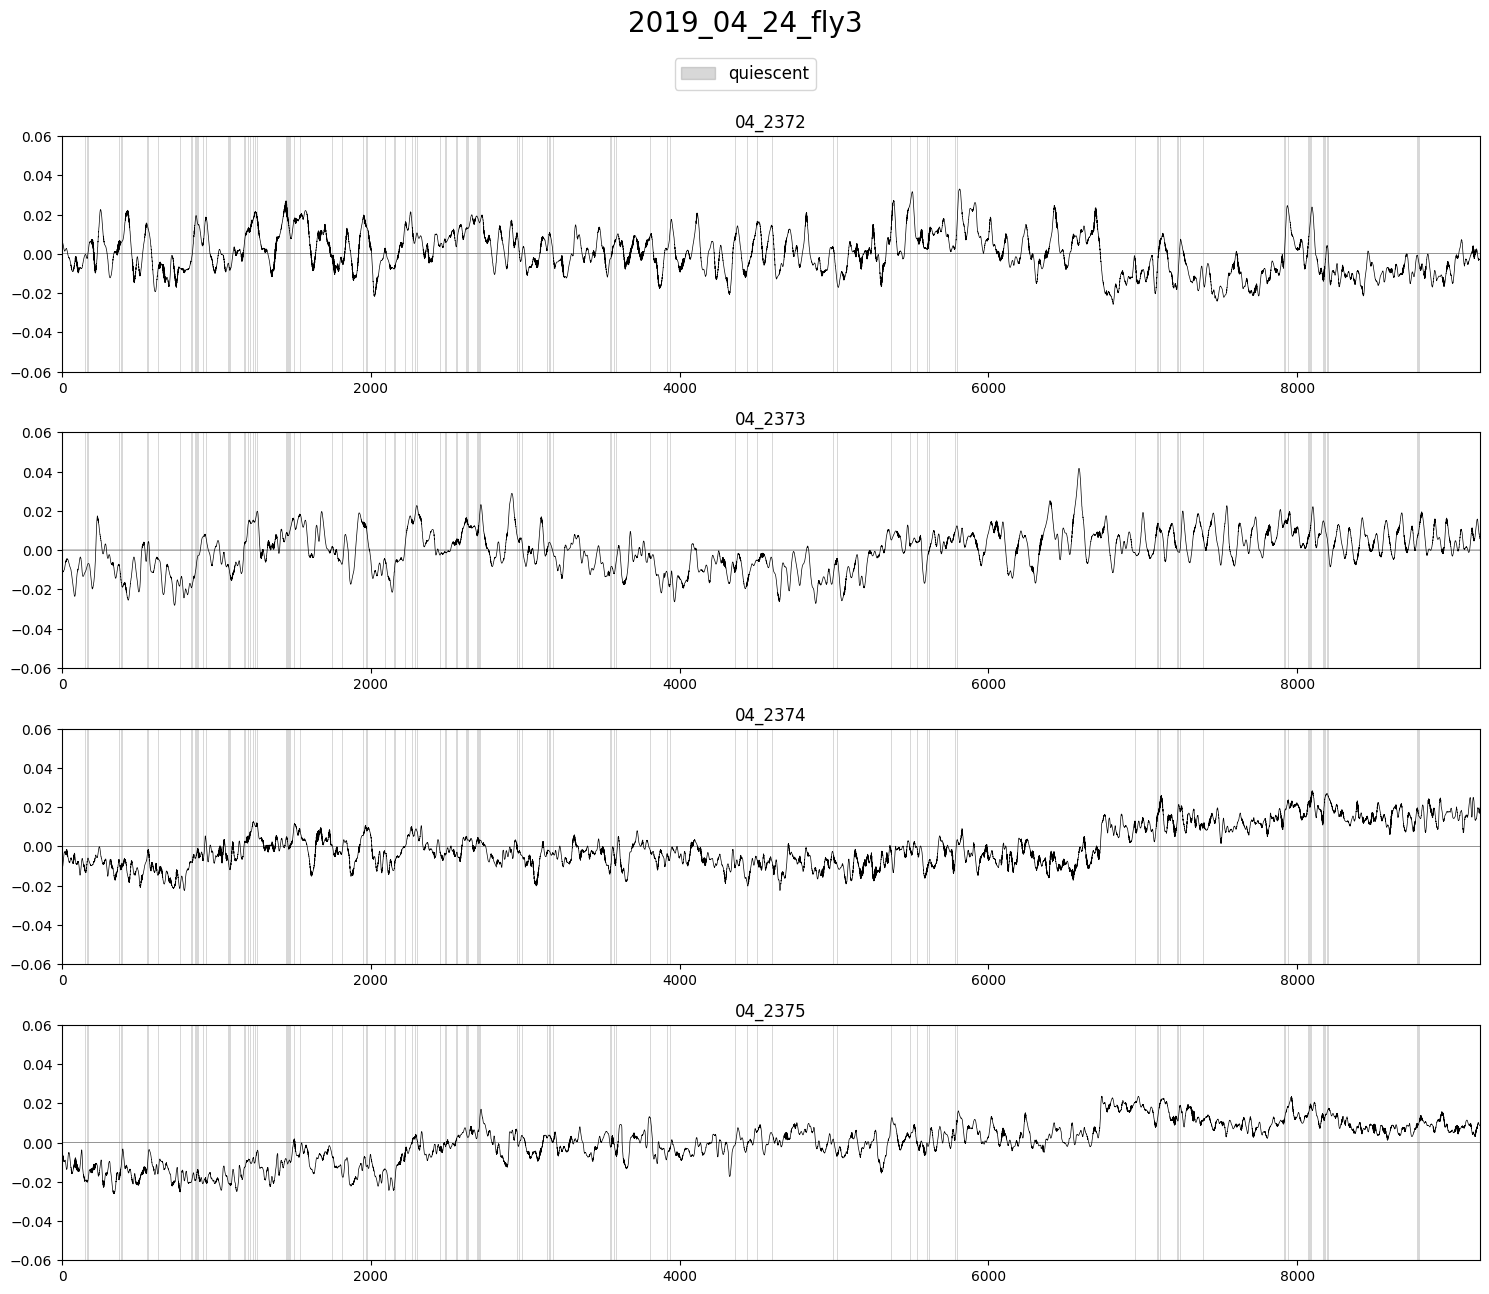

In [34]:
plot_utils.plot_traces(f'{filenames_fl[file_ids_fl.index(plot_id_fl)]}',
					   states_fl[file_ids_fl.index(plot_id_fl)]['?'],
					   [traces_fl[file_ids_fl.index(plot_id_fl)].iloc[:, -4:]],
					   label='quiescent', n_plots=4, plots_per_row=1, top_space=1, ylimits=(-0.06, 0.06))